# BITS Pilani — AIMLCZG523: Machine Learning Operations (MLOps)
## Notebook 03: Production Inference Engine & Serving Verification
**Objectives (Tasks 4 & 6):**
1. Load the serialized end-to-end `heart_disease_pipeline.joblib` artifact.
2. Verify zero train-serving skew by serving raw patient clinical inputs directly.
3. Execute real-time single-patient inference (Low Risk vs High Risk).
4. Perform batch cohort inference and risk stratification.
5. Benchmark inference latency across 100 iterations.

In [1]:
import json
import time
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from src.config import CLEANED_CSV_PATH, MODEL_ARTIFACT_PATH
from src.predict import HeartDiseasePredictor, get_predictor

predictor = get_predictor()
print('Predictor loaded successfully from:', predictor.model_path)
print('Required Features:', predictor.feature_names)

2026-10-15 14:39:58,256 - INFO - Loading pipeline artifact from F:\Nik_assignment\heart assignment\models\heart_disease_pipeline.joblib...


Predictor loaded successfully from: F:\Nik_assignment\heart assignment\models\heart_disease_pipeline.joblib
Required Features: ['age', 'trestbps', 'chol', 'thalach', 'oldpeak', 'sex', 'cp', 'fbs', 'restecg', 'exang', 'slope', 'ca', 'thal']


### 1. Single-Patient Inference: Case 1 (Healthy / Low Risk Profile)
Patient Profile: 41-year-old female, atypical angina (`cp=2`), blood pressure 130 mm Hg, cholesterol 204 mg/dl, max heart rate 172 bpm, zero ST depression.

In [2]:
patient_low_risk = {
    'age': 41.0,
    'sex': 0.0,
    'cp': 2.0,
    'trestbps': 130.0,
    'chol': 204.0,
    'fbs': 0.0,
    'restecg': 2.0,
    'thalach': 172.0,
    'exang': 0.0,
    'oldpeak': 0.0,
    'slope': 1.0,
    'ca': 0.0,
    'thal': 3.0
}
result_low = predictor.predict_single(patient_low_risk)
print('Low Risk Patient Inference Output:')
print(json.dumps(result_low, indent=2))

Low Risk Patient Inference Output:
{
  "prediction": 0,
  "risk_label": "Low Risk (No Heart Disease)",
  "confidence": 0.9363,
  "disease_probability": 0.0637,
  "healthy_probability": 0.9363
}


### 2. Single-Patient Inference: Case 2 (Symptomatic / High Risk Profile)
Patient Profile: 67-year-old male, asymptomatic chest pain (`cp=4`), blood pressure 160 mm Hg, cholesterol 286 mg/dl, max heart rate 108 bpm, ST depression 1.5 mm, 3 colored vessels (`ca=3`).

In [3]:
patient_high_risk = {
    'age': 67.0,
    'sex': 1.0,
    'cp': 4.0,
    'trestbps': 160.0,
    'chol': 286.0,
    'fbs': 0.0,
    'restecg': 2.0,
    'thalach': 108.0,
    'exang': 1.0,
    'oldpeak': 1.5,
    'slope': 2.0,
    'ca': 3.0,
    'thal': 3.0
}
result_high = predictor.predict_single(patient_high_risk)
print('High Risk Patient Inference Output:')
print(json.dumps(result_high, indent=2))

High Risk Patient Inference Output:
{
  "prediction": 1,
  "risk_label": "High Risk (Heart Disease Present)",
  "confidence": 0.9177,
  "disease_probability": 0.9177,
  "healthy_probability": 0.0823
}


### 3. Batch Inference on Patient Cohort
Executing vectorized cohort prediction and enriching dataset with probability distributions and risk classifications.

In [4]:
cohort_df = pd.read_csv(CLEANED_CSV_PATH).sample(n=15, random_state=42)
enriched_cohort = predictor.predict_batch(cohort_df)
print(f'Cohort Size: {len(enriched_cohort)} patients')
enriched_cohort[['age', 'sex', 'cp', 'trestbps', 'prediction', 'confidence', 'disease_probability', 'risk_label']].head(10)

Cohort Size: 15 patients


,age,sex,cp,trestbps,prediction,confidence,disease_probability,risk_label
179,53.0,1.0,3.0,130.0,0,0.775145,0.224855,Low Risk (No Heart Disease)
228,54.0,1.0,4.0,110.0,1,0.815168,0.815168,High Risk (Heart Disease Present)
111,56.0,1.0,4.0,125.0,1,0.813997,0.813997,High Risk (Heart Disease Present)
246,58.0,1.0,4.0,100.0,1,0.625838,0.625838,High Risk (Heart Disease Present)
60,51.0,0.0,4.0,130.0,1,0.655662,0.655662,High Risk (Heart Disease Present)
9,53.0,1.0,4.0,140.0,1,0.814372,0.814372,High Risk (Heart Disease Present)
119,65.0,1.0,4.0,135.0,1,0.941390,0.941390,High Risk (Heart Disease Present)
223,53.0,1.0,4.0,123.0,1,0.957494,0.957494,High Risk (Heart Disease Present)
268,40.0,1.0,4.0,152.0,0,0.615270,0.384730,Low Risk (No Heart Disease)
33,59.0,1.0,4.0,135.0,1,0.596629,0.596629,High Risk (Heart Disease Present)


### 4. Inference Latency & Performance Profiling
Benchmarking 100 consecutive predictions to measure average inference response time.

Inference Latency Profile (100 Iterations):
  - Mean Latency: 15.10 ms
  - Median (p50): 14.75 ms
  - 95th Percentile (p95): 16.98 ms
  - 99th Percentile (p99): 22.50 ms


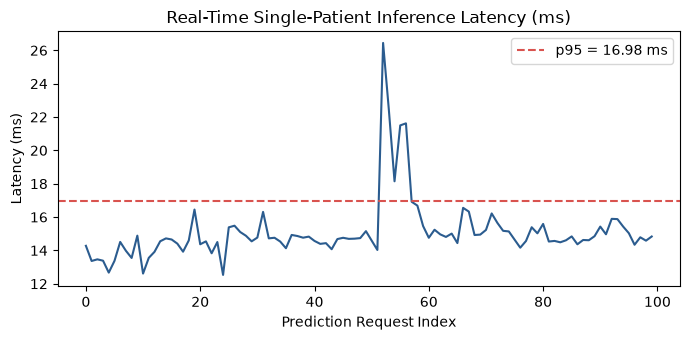

In [5]:
latencies_ms = []
for _ in range(100):
    t0 = time.perf_counter()
    _ = predictor.predict_single(patient_low_risk)
    latencies_ms.append((time.perf_counter() - t0) * 1000)

p50 = np.percentile(latencies_ms, 50)
p95 = np.percentile(latencies_ms, 95)
p99 = np.percentile(latencies_ms, 99)
print('Inference Latency Profile (100 Iterations):')
print(f'  - Mean Latency: {np.mean(latencies_ms):.2f} ms')
print(f'  - Median (p50): {p50:.2f} ms')
print(f'  - 95th Percentile (p95): {p95:.2f} ms')
print(f'  - 99th Percentile (p99): {p99:.2f} ms')

plt.figure(figsize=(7, 3.5))
plt.plot(latencies_ms, color='#2b5c8f', lw=1.5)
plt.axhline(p95, color='#d9534f', linestyle='--', label=f'p95 = {p95:.2f} ms')
plt.title('Real-Time Single-Patient Inference Latency (ms)')
plt.xlabel('Prediction Request Index')
plt.ylabel('Latency (ms)')
plt.legend()
plt.tight_layout()
plt.show()